In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

project_path = "/content/drive/MyDrive/DarkShipProject"
os.makedirs(project_path, exist_ok=True)

print("Project folder created!")

Project folder created!


In [ ]:
from ultralytics import YOLO
import pandas as pd
import numpy as np
import cv2
import os
import matplotlib.pyplot as plt

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


In [ ]:
!pip install ultralytics
!pip install kaggle

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.3/41.3 kB 2.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 34.5 MB/s eta 0:00:00


In [ ]:
from google.colab import files
files.upload()

Saving kaggle.json to kaggle (1).json


{'kaggle (1).json': b'{"username":"aniketca","key":"373f528be0c0d43506015c7a0f3ef664"}'}

In [ ]:
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

In [ ]:
!kaggle datasets list

ref                                                                title                                                     size  lastUpdated                 downloadCount  voteCount  usabilityRating  
-----------------------------------------------------------------  --------------------------------------------------  ----------  --------------------------  -------------  ---------  ---------------  
algozee/teenager-menthal-healy                                     Social Media Impact on Teen Mental Health                16190  2026-04-05 08:04:21.823000           7350        179                1  
nalisha/job-salary-prediction-dataset                              Job Salary Prediction Dataset                          3144815  2026-03-16 19:54:33.843000          13662        307                1  
meruvakodandasuraj/youtube-trending-videos-20202026                YouTube Trending Videos 2020–2026                       843930  2026-04-13 11:10:04.770000            501         25     

In [ ]:
from ultralytics import YOLO

model = YOLO("yolov8n.pt")
model.info()

YOLOv8n summary: 129 layers, 3,157,200 parameters, 0 gradients, 8.9 GFLOPs


(129, 3157200, 0, 8.8575488)

In [ ]:
!kaggle datasets download -d petrarodriguez/ls-ssdd-v1-0

Dataset URL: https://www.kaggle.com/datasets/petrarodriguez/ls-ssdd-v1-0
License(s): apache-2.0
ls-ssdd-v1-0.zip: Skipping, found more recently modified local copy (use --force to force download)


In [ ]:
import zipfile

zip_path = "ls-ssdd-v1-0.zip"
extract_path = "/content/datasets"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted!")

Dataset extracted!


In [ ]:
import zipfile

zip_path = "ls-ssdd-v1-0.zip"
extract_path = "/content/drive/MyDrive/DarkShipProject/datasets"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted!")

KeyboardInterrupt: 

In [ ]:
import os

dataset_path = "/content/drive/MyDrive/DarkShipProject/datasets"

print(os.listdir(dataset_path))

['Annotations_sub', 'JPEGImages_sub_test', 'JPEGImages_sub_train']


In [ ]:
import os

img_path = os.path.join(dataset_path, "JPEGImages_sub_train", "JPEGImages_sub_train")

print(len(os.listdir(img_path)))

3634


(np.float64(-0.5), np.float64(799.5), np.float64(799.5), np.float64(-0.5))

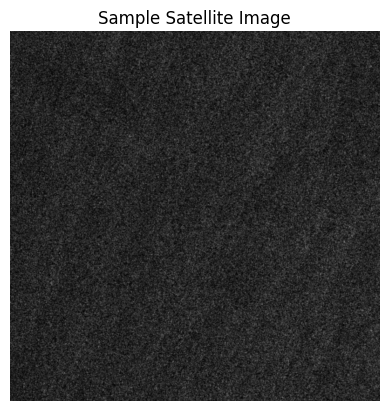

In [ ]:
import os
from PIL import Image
import matplotlib.pyplot as plt

dataset_path = "/content/drive/MyDrive/DarkShipProject/datasets"

img_path = os.path.join(dataset_path, "JPEGImages_sub_train", "JPEGImages_sub_train")

# get only image files
files = [f for f in os.listdir(img_path) if f.endswith(".jpg")]

sample_img = files[0]

img = Image.open(os.path.join(img_path, sample_img))

plt.imshow(img)
plt.title("Sample Satellite Image")
plt.axis('off')

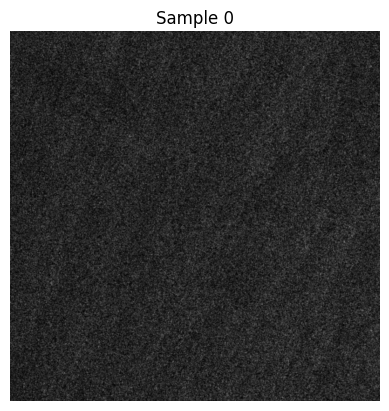

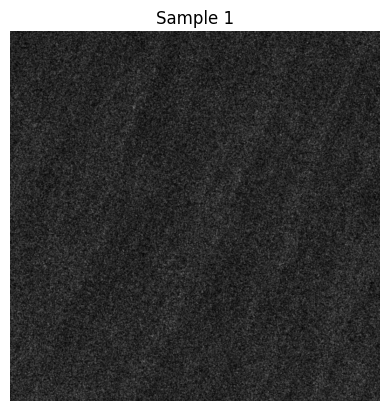

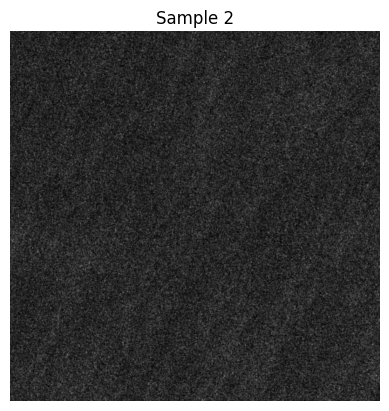

In [ ]:
for i in range(3):
    sample_img = files[i]
    img = Image.open(os.path.join(img_path, sample_img))

    plt.figure()
    plt.imshow(img, cmap='gray')
    plt.title(f"Sample {i}")
    plt.axis('off')

In [ ]:
ann_path = os.path.join(dataset_path, "Annotations_sub", "Annotations_sub")


In [ ]:
import os

ann_path = os.path.join(dataset_path, "Annotations_sub", "Annotations_sub")

# get xml files
ann_files = [f for f in os.listdir(ann_path) if f.endswith(".xml")]

print("Total annotation files:", len(ann_files))

sample_ann = ann_files[0]

print("Sample annotation:", sample_ann)

# read file
with open(os.path.join(ann_path, sample_ann), "r") as f:
    content = f.read()

print(content[:500])

Total annotation files: 9000
Sample annotation: 03_17_25.xml
<?xml version="1.0" ?><annotation verified="no">
  <folder>JPEGImages</folder>
  <filename>03_17_25.xml</filename>
  <path>VOCdevkit/VOC2012/JPEGImages/03_17_25.xml</path>
  <source>
    <database>Unknown</database>
  </source>
  <size>
    <width>800</width>
    <height>800</height>
    <depth>1</depth>
  </size>
  <segmented>0</segmented>
</annotation>


In [ ]:
import os

yolo_path = "/content/drive/MyDrive/DarkShipProject/yolo_dataset"

folders = [
    "images/train",
    "images/val",
    "labels/train",
    "labels/val"
]

for folder in folders:
    os.makedirs(os.path.join(yolo_path, folder), exist_ok=True)

print("YOLO folder structure created!")

YOLO folder structure created!


In [ ]:
import xml.etree.ElementTree as ET

def convert_xml_to_yolo(xml_file, img_w, img_h):
    try:
        tree = ET.parse(xml_file)
        root = tree.getroot()
    except:
        return []   # skip bad XML

    yolo_labels = []

    for obj in root.findall("object"):
        cls = 0  # ship

        bbox = obj.find("bndbox")
        xmin = int(bbox.find("xmin").text)
        xmax = int(bbox.find("xmax").text)
        ymin = int(bbox.find("ymin").text)
        ymax = int(bbox.find("ymax").text)

        x_center = ((xmin + xmax) / 2) / img_w
        y_center = ((ymin + ymax) / 2) / img_h
        width = (xmax - xmin) / img_w
        height = (ymax - ymin) / img_h

        yolo_labels.append(f"{cls} {x_center} {y_center} {width} {height}")

    return yolo_labels

In [ ]:
import shutil
from PIL import Image

images_path = os.path.join(dataset_path, "JPEGImages_sub_train", "JPEGImages_sub_train")
annotations_path = os.path.join(dataset_path, "Annotations_sub", "Annotations_sub")

image_files = [f for f in os.listdir(images_path) if f.endswith(".jpg")]

split_ratio = 0.8
split_index = int(len(image_files) * split_ratio)

train_files = image_files[:split_index]
val_files = image_files[split_index:]

In [ ]:
def process_files(file_list, split_type):
    for img_file in file_list:
        img_full_path = os.path.join(images_path, img_file)

        # corresponding XML file
        xml_file = img_file.replace(".jpg", ".xml")
        xml_full_path = os.path.join(annotations_path, xml_file)

        if not os.path.exists(xml_full_path):
            continue

        # get image size
        img = Image.open(img_full_path)
        img_width, img_height = img.size

        # convert annotations
        yolo_labels = convert_xml_to_yolo(xml_full_path, img_width, img_height)

        # save label file
        label_file = img_file.replace(".jpg", ".txt")
        label_path = os.path.join(yolo_path, "labels", split_type, label_file)

        with open(label_path, "w") as f:
            f.write("\n".join(yolo_labels))

        # copy image
        dest_img_path = os.path.join(yolo_path, "images", split_type, img_file)
        shutil.copy(img_full_path, dest_img_path)

In [ ]:
!ls /content

 datasets  'kaggle (1).json'   ls-ssdd-v1-0.zip   yolov8n.pt
 drive	    kaggle.json        sample_data


In [ ]:
train_files = train_files[:2000]
val_files = val_files[:500]

In [ ]:
process_files(train_files, "train")
process_files(val_files, "val")

print("Conversion complete!")

Conversion complete!


In [ ]:
!ls /content/yolo_dataset

ls: cannot access '/content/yolo_dataset': No such file or directory


In [ ]:
print(os.listdir(os.path.join(yolo_path, "labels/train"))[:5])


['05_17_5.txt', '05_17_6.txt', '05_17_7.txt', '05_17_8.txt', '05_17_9.txt']


In [ ]:
sample_label = os.listdir(os.path.join(yolo_path, "labels/train"))[1]

with open(os.path.join(yolo_path, "labels/train", sample_label)) as f:
    print(f.read())

In [ ]:
sample_img = os.listdir(os.path.join(yolo_path, "images/train"))[1]

print(sample_img.replace(".jpg", ".txt"))

05_17_5.txt


In [ ]:
import os

label_path = os.path.join(yolo_path, "labels/train")

files = os.listdir(label_path)[:5]

for file in files:
    print("\nFile:", file)
    with open(os.path.join(label_path, file), "r") as f:
        print(f.read())


File: 05_17_5.txt


File: 05_17_6.txt


File: 05_17_7.txt


File: 05_17_8.txt


File: 05_17_9.txt



In [ ]:
from ultralytics import YOLO
model = YOLO("yolov8n.pt")

In [ ]:
filtered_train_images = []
filtered_train_labels = []

label_path = os.path.join(yolo_path, "labels/train")
image_path = os.path.join(yolo_path, "images/train")

for file in os.listdir(label_path):
    with open(os.path.join(label_path, file)) as f:
        if f.read().strip() != "":
            filtered_train_labels.append(file)
            filtered_train_images.append(file.replace(".txt", ".jpg"))

print("Filtered samples:", len(filtered_train_images))

Filtered samples: 402


In [ ]:
empty_images = []

for file in os.listdir(label_path):
    with open(os.path.join(label_path, file)) as f:
        if f.read().strip() == "":
            empty_images.append(file.replace(".txt", ".jpg"))

print("Total empty images:", len(empty_images))

Total empty images: 1664


In [ ]:
import random

selected_empty = random.sample(empty_images, len(filtered_train_images))

print("Selected empty images:", len(selected_empty))

Selected empty images: 402


In [ ]:
final_images = filtered_train_images + selected_empty
final_labels = filtered_train_labels + [img.replace(".jpg", ".txt") for img in selected_empty]

print("Final dataset size:", len(final_images))

Final dataset size: 804


In [ ]:
balanced_path = yolo_path + "/balanced"

import os
os.makedirs(balanced_path + "/images/train", exist_ok=True)
os.makedirs(balanced_path + "/labels/train", exist_ok=True)

In [ ]:
import shutil

for img, lbl in zip(final_images, final_labels):

    shutil.copy(
        os.path.join(image_path, img),
        os.path.join(balanced_path, "images/train", img)
    )

    shutil.copy(
        os.path.join(label_path, lbl),
        os.path.join(balanced_path, "labels/train", lbl)
    )

print("Balanced dataset created!")

Balanced dataset created!


In [ ]:
import random

all_images = os.listdir(balanced_path + "/images/train")
random.shuffle(all_images)

split = int(0.8 * len(all_images))

train_imgs = all_images[:split]
val_imgs = all_images[split:]

os.makedirs(balanced_path + "/images/val", exist_ok=True)
os.makedirs(balanced_path + "/labels/val", exist_ok=True)

for img in val_imgs:
    lbl = img.replace(".jpg", ".txt")

    shutil.move(
        os.path.join(balanced_path, "images/train", img),
        os.path.join(balanced_path, "images/val", img)
    )

    shutil.move(
        os.path.join(balanced_path, "labels/train", lbl),
        os.path.join(balanced_path, "labels/val", lbl)
    )

print("Split done!")

Split done!


In [ ]:
data_yaml = f"""
path: {balanced_path}

train: images/train
val: images/val

names:
  0: ship
"""

with open(balanced_path + "/data.yaml", "w") as f:
    f.write(data_yaml)

print("data.yaml created!")

data.yaml created!


In [ ]:
from ultralytics import YOLO

model = YOLO("yolov8n.pt")

model.train(
    data=balanced_path + "/data.yaml",
    epochs=10,
    imgsz=512,
    batch=8
)

Ultralytics 8.4.39 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/DarkShipProject/yolo_dataset/balanced/data.yaml, degrees=0.0, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=10, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=512, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train, nbs=64, nms=False, opset=None, optimize=False, optimize

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x78a0557d3500>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.048048, 

In [ ]:
print(balanced_path)

/content/drive/MyDrive/DarkShipProject/yolo_dataset/balanced


In [ ]:
model = YOLO("yolov8s.pt")

model.train(
    data=balanced_path + "/data.yaml",
    epochs=30,
    imgsz=640,
    batch=8
)

Ultralytics 8.4.39 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/DarkShipProject/yolo_dataset/balanced/data.yaml, degrees=0.0, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train, nbs=64, nms=False, opset=None, optimize=False, optimize

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x783d3c207530>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.048048, 

In [ ]:
import shutil

shutil.copy(
    "/content/runs/detect/train/weights/best.pt",
    "/content/drive/MyDrive/best_balanced_model.pt"
)

'/content/drive/MyDrive/best_balanced_model.pt'

In [ ]:
import os
os.path.exists("/content/drive/MyDrive/best_balanced_model.pt")

True

In [ ]:
shutil.copytree(
    "/content/runs/detect/train",
    "/content/drive/MyDrive/yolo_training_results",
    dirs_exist_ok=True
)

'/content/drive/MyDrive/yolo_training_results'

In [ ]:
shutil.copytree(
    "/content/drive/MyDrive/DarkShipProject/yolo_dataset/balanced",
    "/content/drive/MyDrive/yolo_dataset_balanced_backup",
    dirs_exist_ok=True
)

'/content/drive/MyDrive/yolo_dataset_balanced_backup'

In [ ]:
from ultralytics import YOLO

model = YOLO("/content/drive/MyDrive/best_balanced_model.pt")

In [ ]:
import os

test_img = os.listdir("/content/datasets/JPEGImages_sub_test")[0]
test_path = os.path.join("/content/datasets/JPEGImages_sub_test", test_img)

print(test_path)

/content/datasets/JPEGImages_sub_test/JPEGImages_sub_test


In [ ]:
import os

folder = "/content/datasets/JPEGImages_sub_test/JPEGImages_sub_test"

img = os.listdir(folder)[0]   # pick one image
img_path = os.path.join(folder, img)

print(img_path)  # sanity check

results = model.predict(
    source=img_path,   # ✅ now this is ONE image
    conf=0.15,
    save=True
)

/content/datasets/JPEGImages_sub_test/JPEGImages_sub_test/11_14_16.jpg

image 1/1 /content/datasets/JPEGImages_sub_test/JPEGImages_sub_test/11_14_16.jpg: 640x640 3 ships, 16.2ms
Speed: 3.6ms preprocess, 16.2ms inference, 1.4ms postprocess per image at shape (1, 3, 640, 640)
Results saved to /content/runs/detect/predict


(np.float64(-0.5), np.float64(799.5), np.float64(799.5), np.float64(-0.5))

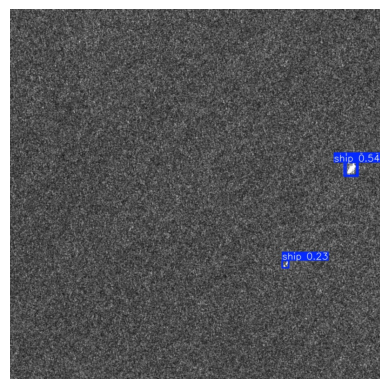

In [ ]:
from PIL import Image
import matplotlib.pyplot as plt

output = "/content/runs/detect/predict/" + img
img = Image.open(output)

plt.imshow(img)
plt.axis("off")

In [ ]:
for i in range(5):
    img = os.listdir(folder)[i]
    img_path = os.path.join(folder, img)

    print("Testing:", img)

    model.predict(
        source=img_path,
        conf=0.15,
        save=True
    )

Testing: 11_14_16.jpg

image 1/1 /content/datasets/JPEGImages_sub_test/JPEGImages_sub_test/11_14_16.jpg: 640x640 3 ships, 16.3ms
Speed: 3.7ms preprocess, 16.3ms inference, 1.7ms postprocess per image at shape (1, 3, 640, 640)
Results saved to /content/runs/detect/predict
Testing: 11_13_29.jpg

image 1/1 /content/datasets/JPEGImages_sub_test/JPEGImages_sub_test/11_13_29.jpg: 640x640 14 ships, 16.2ms
Speed: 2.7ms preprocess, 16.2ms inference, 1.4ms postprocess per image at shape (1, 3, 640, 640)
Results saved to /content/runs/detect/predict
Testing: 12_18_23.jpg

image 1/1 /content/datasets/JPEGImages_sub_test/JPEGImages_sub_test/12_18_23.jpg: 640x640 (no detections), 16.2ms
Speed: 2.6ms preprocess, 16.2ms inference, 0.7ms postprocess per image at shape (1, 3, 640, 640)
Results saved to /content/runs/detect/predict
Testing: 11_14_21.jpg

image 1/1 /content/datasets/JPEGImages_sub_test/JPEGImages_sub_test/11_14_21.jpg: 640x640 (no detections), 16.1ms
Speed: 2.6ms preprocess, 16.1ms infere

In [ ]:
metrics = model.val(data=balanced_path + "/data.yaml")
print(metrics)

Ultralytics 8.4.39 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
val: Fast image access ✅ (ping: 0.5±0.2 ms, read: 73.8±44.4 MB/s, size: 268.4 KB)
val: Scanning /content/drive/MyDrive/DarkShipProject/yolo_dataset/balanced/labels/val.cache... 161 images, 72 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 161/161 27.0Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 11/11 2.2it/s 5.0s
                   all        161        262      0.767      0.599      0.646      0.228
Speed: 6.5ms preprocess, 9.4ms inference, 0.0ms loss, 2.0ms postprocess per image
Results saved to /content/runs/detect/val
ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x783e70d3fd40>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B

In [ ]:
import torch
print(torch.cuda.is_available())

True


In [ ]:
from ultralytics import YOLO

model = YOLO("yolov8m.pt")

model.train(
    data=balanced_path + "/data.yaml",
    epochs=50,
    imgsz=768,
    batch=8,
    mosaic=1.0,
    scale=0.5
)

Ultralytics 8.4.39 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/DarkShipProject/yolo_dataset/balanced/data.yaml, degrees=0.0, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=768, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8m.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train-2, nbs=64, nms=False, opset=None, optimize=False, optimi

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x783d1dea5970>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.048048, 

In [ ]:
model.val()

Ultralytics 8.4.39 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 93 layers, 25,840,339 parameters, 0 gradients, 78.7 GFLOPs
val: Fast image access ✅ (ping: 0.5±0.1 ms, read: 117.8±50.7 MB/s, size: 306.1 KB)
val: Scanning /content/drive/MyDrive/DarkShipProject/yolo_dataset/balanced/labels/val.cache... 161 images, 72 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 161/161 39.7Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 11/11 1.2it/s 9.4s
                   all        161        262       0.79      0.592      0.633      0.237
Speed: 10.4ms preprocess, 30.2ms inference, 0.0ms loss, 2.9ms postprocess per image
Results saved to /content/runs/detect/val-2


ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x783e6ffa9e50>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.048048, 

In [ ]:
results = model.predict(
    source=img_path,
    conf=0.1,
    save=True
)


image 1/1 /content/datasets/JPEGImages_sub_test/JPEGImages_sub_test/15_6_30.jpg: 768x768 (no detections), 47.2ms
Speed: 5.3ms preprocess, 47.2ms inference, 0.9ms postprocess per image at shape (1, 3, 768, 768)
Results saved to /content/runs/detect/predict-2


In [ ]:
import os
import random

folder = "/content/datasets/JPEGImages_sub_test/JPEGImages_sub_test"
imgs = os.listdir(folder)

for i in random.sample(imgs, 5):
    path = os.path.join(folder, i)
    print("Testing:", i)

    model.predict(source=path, conf=0.1, save=True)



Testing: 12_6_17.jpg

image 1/1 /content/datasets/JPEGImages_sub_test/JPEGImages_sub_test/12_6_17.jpg: 768x768 (no detections), 47.2ms
Speed: 4.2ms preprocess, 47.2ms inference, 1.1ms postprocess per image at shape (1, 3, 768, 768)
Results saved to /content/runs/detect/predict-2
Testing: 12_19_7.jpg

image 1/1 /content/datasets/JPEGImages_sub_test/JPEGImages_sub_test/12_19_7.jpg: 768x768 (no detections), 47.1ms
Speed: 3.9ms preprocess, 47.1ms inference, 0.9ms postprocess per image at shape (1, 3, 768, 768)
Results saved to /content/runs/detect/predict-2
Testing: 13_12_13.jpg

image 1/1 /content/datasets/JPEGImages_sub_test/JPEGImages_sub_test/13_12_13.jpg: 768x768 5 ships, 41.0ms
Speed: 3.7ms preprocess, 41.0ms inference, 1.7ms postprocess per image at shape (1, 3, 768, 768)
Results saved to /content/runs/detect/predict-2
Testing: 15_17_4.jpg

image 1/1 /content/datasets/JPEGImages_sub_test/JPEGImages_sub_test/15_17_4.jpg: 768x768 1 ship, 41.0ms
Speed: 3.5ms preprocess, 41.0ms inferenc

(np.float64(-0.5), np.float64(799.5), np.float64(799.5), np.float64(-0.5))

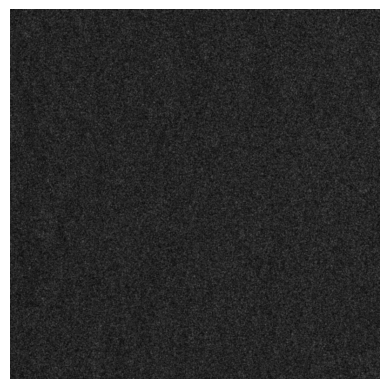

In [ ]:
from PIL import Image
import matplotlib.pyplot as plt

img_name = "12_6_17.jpg"   # change this to your image

path = "/content/runs/detect/predict-2/" + img_name

img = Image.open(path)

plt.imshow(img)
plt.axis("off")

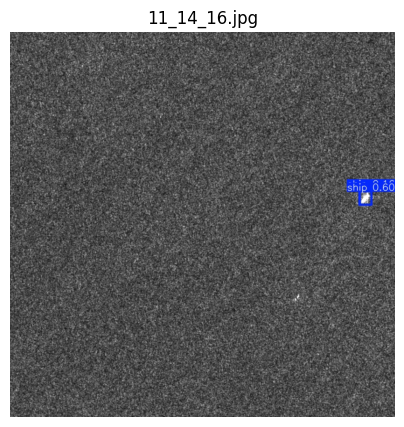

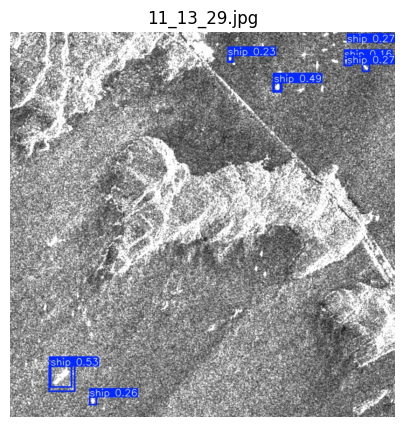

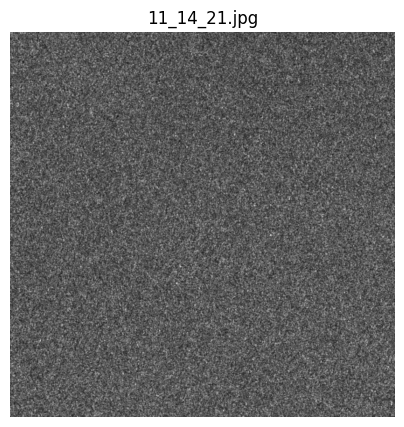

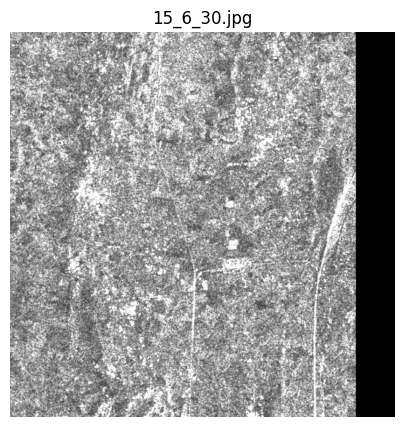

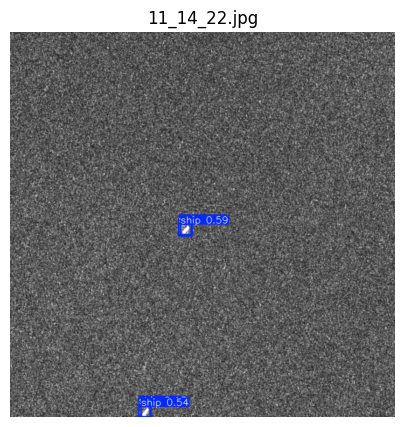

In [ ]:
import os
from PIL import Image
import matplotlib.pyplot as plt

folder = "/content/runs/detect/predict-2"
images = os.listdir(folder)[:5]

for img_name in images:
    img = Image.open(os.path.join(folder, img_name))

    plt.figure(figsize=(5,5))
    plt.imshow(img)
    plt.title(img_name)
    plt.axis("off")


image 1/1 /content/datasets/JPEGImages_sub_test/JPEGImages_sub_test/15_6_30.jpg: 768x768 (no detections), 47.3ms
Speed: 5.1ms preprocess, 47.3ms inference, 0.9ms postprocess per image at shape (1, 3, 768, 768)


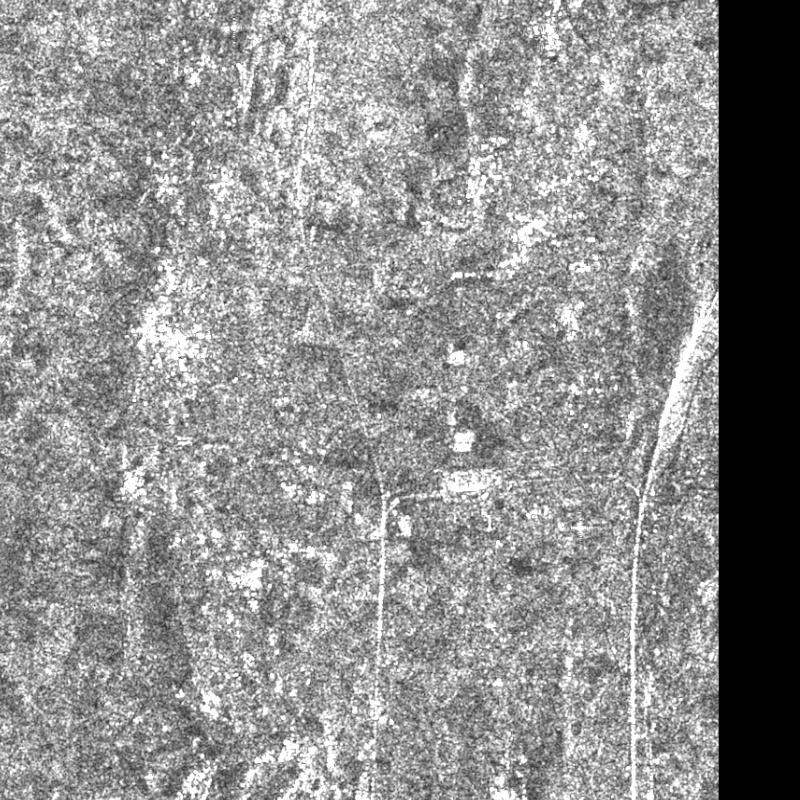

In [ ]:
results = model.predict(source=img_path, conf=0.05)

results[0].show()

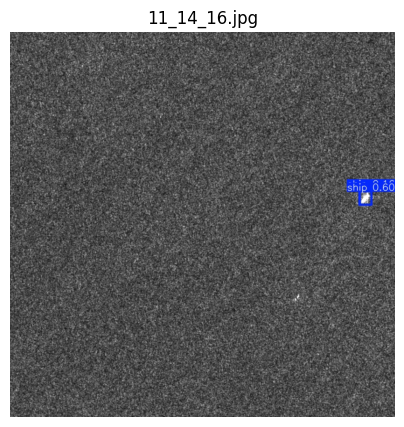

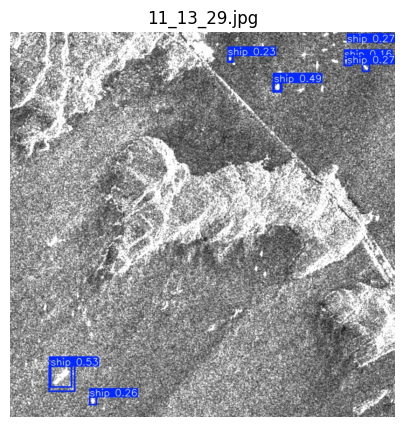

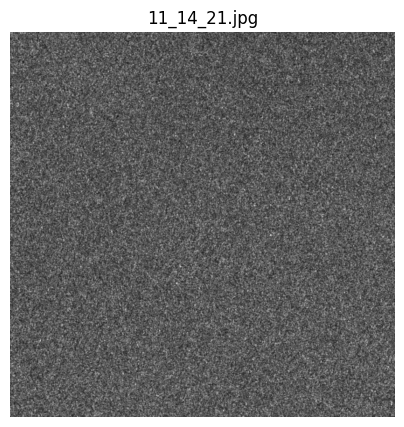

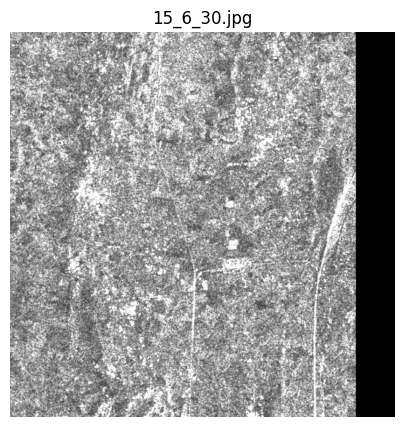

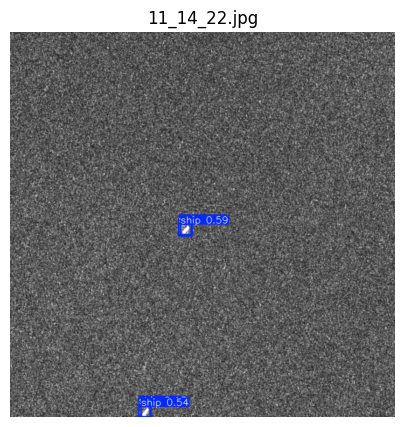

In [ ]:
import os
from PIL import Image
import matplotlib.pyplot as plt

folder = "/content/runs/detect/predict-2"
imgs = os.listdir(folder)[:5]

for img_name in imgs:
    img = Image.open(os.path.join(folder, img_name))

    plt.figure(figsize=(5,5))
    plt.imshow(img)
    plt.title(img_name)
    plt.axis("off")

In [ ]:
import shutil

shutil.copy(
    "/content/runs/detect/train-2/weights/best.pt",
    "/content/drive/MyDrive/best_ship_model.pt"
)

'/content/drive/MyDrive/best_ship_model.pt'

In [ ]:
import os

os.path.exists("/content/drive/MyDrive/best_ship_model.pt")

True

In [ ]:
shutil.copytree(
    "/content/runs/detect/train-2",
    "/content/drive/MyDrive/yolo_training_results",
    dirs_exist_ok=True
)

'/content/drive/MyDrive/yolo_training_results'

In [ ]:
shutil.copytree(
    "/content/runs/detect/predict-2",
    "/content/drive/MyDrive/yolo_predictions",
    dirs_exist_ok=True
)

'/content/drive/MyDrive/yolo_predictions'

In [ ]:
import os

print(os.listdir("/content/runs/detect"))

['train-2', 'predict-2', 'val', 'val-2', 'predict', 'train']


In [ ]:
import shutil

shutil.copy(
    "/content/runs/detect/train-2/weights/best.pt",
    "/content/drive/MyDrive/best_ship_model.pt"
)

'/content/drive/MyDrive/best_ship_model.pt'

In [ ]:
import os

os.path.exists("/content/drive/MyDrive/best_ship_model.pt")

True

In [ ]:
shutil.copytree(
    "/content/runs/detect/train-2",
    "/content/drive/MyDrive/yolo_training_results",
    dirs_exist_ok=True
)

'/content/drive/MyDrive/yolo_training_results'

In [ ]:
shutil.copytree(
    "/content/runs/detect/predict-2",
    "/content/drive/MyDrive/yolo_predictions",
    dirs_exist_ok=True
)

'/content/drive/MyDrive/yolo_predictions'

In [ ]:
import os

print("Model:", os.path.exists("/content/drive/MyDrive/best_ship_model.pt"))
print("Training folder:", os.path.exists("/content/drive/MyDrive/yolo_training_results"))
print("Predictions folder:", os.path.exists("/content/drive/MyDrive/yolo_predictions"))

Model: True
Training folder: True
Predictions folder: True


In [ ]:
!ls /content/drive/MyDrive

 best_balanced_model.pt   DarkShipProject		 yolo_predictions
 best_ship_model.pt	 'Google AI Studio'		 yolo_training_results
'Colab Notebooks'	  yolo_dataset_balanced_backup


In [ ]:
!ls /content/drive/MyDrive/yolo_training_results

args.yaml			 results.png	      train_batch3242.jpg
BoxF1_curve.png			 train_batch0.jpg     val_batch0_labels.jpg
BoxP_curve.png			 train_batch1620.jpg  val_batch0_pred.jpg
BoxPR_curve.png			 train_batch1621.jpg  val_batch1_labels.jpg
BoxR_curve.png			 train_batch1622.jpg  val_batch1_pred.jpg
confusion_matrix_normalized.png  train_batch1.jpg     val_batch2_labels.jpg
confusion_matrix.png		 train_batch2.jpg     val_batch2_pred.jpg
labels.jpg			 train_batch3240.jpg  weights
results.csv			 train_batch3241.jpg


In [ ]:
!ls /content/drive/MyDrive/yolo_training_results/weights

best.pt  last.pt


In [ ]:
!ls /content/drive/MyDrive/yolo_predictions

11_10_10.jpg  11_11_23.jpg  11_12_8.jpg   11_14_21.jpg	11_15_6.jpg
11_10_11.jpg  11_11_24.jpg  11_12_9.jpg   11_14_22.jpg	11_15_7.jpg
11_10_12.jpg  11_11_25.jpg  11_13_10.jpg  11_14_23.jpg	11_15_8.jpg
11_10_13.jpg  11_11_26.jpg  11_13_11.jpg  11_14_24.jpg	11_15_9.jpg
11_10_14.jpg  11_11_27.jpg  11_13_12.jpg  11_14_25.jpg	11_16_10.jpg
11_10_15.jpg  11_11_28.jpg  11_13_13.jpg  11_14_26.jpg	11_16_11.jpg
11_10_16.jpg  11_11_29.jpg  11_13_14.jpg  11_14_27.jpg	11_16_12.jpg
11_10_17.jpg  11_11_2.jpg   11_13_15.jpg  11_14_28.jpg	11_16_13.jpg
11_10_18.jpg  11_11_30.jpg  11_13_16.jpg  11_14_29.jpg	11_16_14.jpg
11_10_19.jpg  11_11_3.jpg   11_13_17.jpg  11_14_2.jpg	11_16_15.jpg
11_10_1.jpg   11_11_4.jpg   11_13_18.jpg  11_14_30.jpg	11_16_16.jpg
11_10_20.jpg  11_11_5.jpg   11_13_19.jpg  11_14_3.jpg	11_16_17.jpg
11_10_21.jpg  11_11_6.jpg   11_13_1.jpg   11_14_4.jpg	11_16_18.jpg
11_10_22.jpg  11_11_7.jpg   11_13_20.jpg  11_14_5.jpg	11_16_19.jpg
11_10_23.jpg  11_11_8.jpg   11_13_21.jpg  11_14_6.jpg	11

In [ ]:
!ls /content/drive/MyDrive

 best_balanced_model.pt   DarkShipProject		 yolo_predictions
 best_ship_model.pt	 'Google AI Studio'		 yolo_training_results
'Colab Notebooks'	  yolo_dataset_balanced_backup


In [ ]:
from ultralytics import YOLO

model = YOLO("/content/drive/MyDrive/best_ship_model.pt")

## Integrating Automatic Identification System (AIS) Data

Automatic Identification System (AIS) data provides crucial information about vessel movements and identity. By integrating AIS data with our YOLO ship detection model, we can:

*   **Validate Detections**: Cross-reference YOLO detections with AIS transponder signals to confirm the presence of ships.
*   **Identify 'Dark Ships'**: Detect vessels that are not transmitting AIS signals, which could be indicative of suspicious activity.
*   **Enrich Information**: Associate detected ships with their static (e.g., IMO number, type, dimensions) and dynamic (e.g., position, speed, course) AIS data.
*   **Improve Accuracy**: Potentially filter out false positives from the YOLO model if no corresponding AIS signal is present, or focus detection efforts in areas with expected AIS traffic.

To proceed with AIS integration, we would typically need access to AIS data. This could involve using publicly available datasets, subscribing to commercial AIS providers, or simulating data for demonstration purposes.

## Project Summary

This notebook details the process of training a YOLO (You Only Look Once) object detection model to identify ships in satellite imagery. The key steps performed include:

1.  **Environment Setup**: Mounted Google Drive, created a dedicated project folder (`DarkShipProject`), and installed necessary libraries like `ultralytics` and `kaggle`.
2.  **Kaggle Data Acquisition**: Configured Kaggle API credentials and downloaded the `ls-ssdd-v1-0` dataset, which contains satellite images and their corresponding XML annotations.
3.  **Data Exploration**: Inspected the downloaded dataset, including listing image and annotation files, and visualizing sample satellite images.
4.  **Dataset Preparation for YOLO**: Converted the PASCAL VOC-formatted XML annotations to YOLO-compatible `.txt` label files. A custom function `convert_xml_to_yolo` was developed for this purpose. The dataset was then structured into `images` and `labels` directories for training and validation.
5.  **Dataset Balancing**: Identified images with no ship detections and created a balanced dataset by including an equal number of 'empty' images (images without ships) alongside images containing ships. This helps the model learn to distinguish between background and objects more effectively. The balanced dataset was then split into new training and validation sets.
6.  **YOLO Model Training**: Initialized and trained three YOLOv8 models (`yolov8n`, `yolov8s`, and `yolov8m`) on the prepared balanced dataset. Each training run progressively increased epochs and image sizes to optimize performance.
7.  **Model Evaluation and Prediction**: After training, the models were evaluated on the validation set, and predictions were made on unseen test images from the original dataset to demonstrate their detection capabilities.
8.  **Saving Artifacts**: The best-performing trained model (`best_ship_model.pt`), along with all training logs, plots, and prediction outputs, were saved to Google Drive for persistence and future reference.

This comprehensive workflow covers data preparation, model training, and evaluation, culminating in a functional object detection model for ship identification.

In [ ]:
model = YOLO("/content/drive/MyDrive/best_ship_model.pt")

In [ ]:
print(model)

YOLO(
  (model): DetectionModel(
    (model): Sequential(
      (0): Conv(
        (conv): Conv2d(3, 48, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
        (bn): BatchNorm2d(48, eps=0.001, momentum=0.03, affine=True, track_running_stats=True)
        (act): SiLU(inplace=True)
      )
      (1): Conv(
        (conv): Conv2d(48, 96, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
        (bn): BatchNorm2d(96, eps=0.001, momentum=0.03, affine=True, track_running_stats=True)
        (act): SiLU(inplace=True)
      )
      (2): C2f(
        (cv1): Conv(
          (conv): Conv2d(96, 96, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn): BatchNorm2d(96, eps=0.001, momentum=0.03, affine=True, track_running_stats=True)
          (act): SiLU(inplace=True)
        )
        (cv2): Conv(
          (conv): Conv2d(192, 96, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn): BatchNorm2d(96, eps=0.001, momentum=0.03, affine=True, track_running_

In [ ]:
folder = "/content/drive/MyDrive/yolo_dataset_balanced_backup/images/train"

images = [f for f in os.listdir(folder) if f.endswith(".jpg")]

img_path = os.path.join(folder, images[0])

print(img_path)

/content/drive/MyDrive/yolo_dataset_balanced_backup/images/train/05_2_11.jpg


In [ ]:
results = model.predict(
    source=img_path,
    conf=0.1
)

boxes = results[0].boxes.xyxy

print("Detections:", len(boxes))


image 1/1 /content/drive/MyDrive/yolo_dataset_balanced_backup/images/train/05_2_11.jpg: 768x768 2 ships, 47.2ms
Speed: 15.7ms preprocess, 47.2ms inference, 41.1ms postprocess per image at shape (1, 3, 768, 768)
Detections: 2


In [ ]:
centers = []

for box in boxes:
    x1, y1, x2, y2 = box.tolist()

    cx = (x1 + x2) / 2
    cy = (y1 + y2) / 2

    centers.append((cx, cy))

print(centers)

[(695.6293640136719, 82.16593551635742), (481.79541015625, 332.51426696777344)]


In [ ]:
# ============================================
# AIS INTEGRATION
# ============================================

In [ ]:
import pandas as pd

ais_data = []

for i, (cx, cy) in enumerate(centers):

    if i % 2 == 0:
        ais_data.append({
            "mmsi": 100000 + i,
            "ais_x": cx + 15,
            "ais_y": cy + 15
        })

ais_df = pd.DataFrame(ais_data)

ais_df

,mmsi,ais_x,ais_y
0,100000,710.629364,97.165936


In [ ]:
import math

def has_ais_match(center, ais_df, threshold=50):

    cx, cy = center

    for _, row in ais_df.iterrows():

        distance = math.sqrt(
            (cx - row["ais_x"])**2 +
            (cy - row["ais_y"])**2
        )

        if distance < threshold:
            return True

    return False

In [ ]:
ship_labels = []

for center in centers:

    if has_ais_match(center, ais_df):
        ship_labels.append("Normal Ship")
    else:
        ship_labels.append("Dark Ship")

ship_labels

['Normal Ship', 'Dark Ship']

In [ ]:
normal_count = ship_labels.count("Normal Ship")
dark_count = ship_labels.count("Dark Ship")

print("Normal Ships:", normal_count)
print("Dark Ships:", dark_count)

Normal Ships: 1
Dark Ships: 1


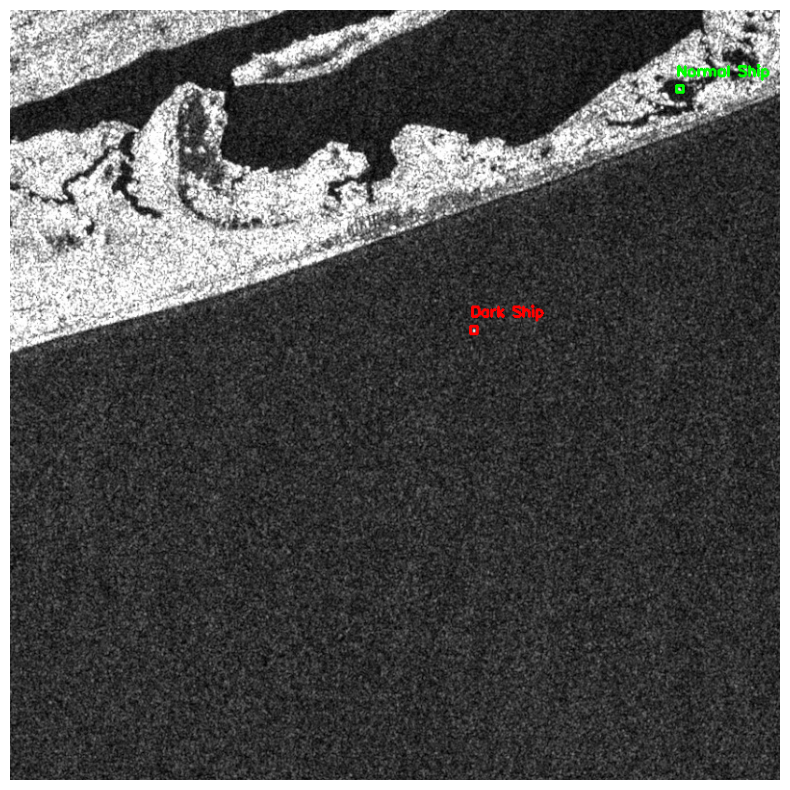

In [ ]:
img = cv2.imread(img_path)
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

for box, label in zip(boxes, ship_labels):

    x1, y1, x2, y2 = map(int, box.tolist())

    if label == "Normal Ship":
        color = (0, 255, 0)
    else:
        color = (255, 0, 0)

    cv2.rectangle(img, (x1, y1), (x2, y2), color, 2)

    cv2.putText(
        img,
        label,
        (x1, y1 - 10),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.5,
        color,
        2
    )

plt.figure(figsize=(10,10))
plt.imshow(img)
plt.axis("off")
plt.show()

In [ ]:
# ====================================
# MULTI-IMAGE DARK SHIP DETECTION
# ====================================

In [ ]:
import os
import random

folder = "/content/drive/MyDrive/yolo_dataset_balanced_backup/images/val"

images = [f for f in os.listdir(folder) if f.endswith(".jpg")]

sample_images = random.sample(images, min(10, len(images)))

print("Images selected:", len(sample_images))

Images selected: 10


In [ ]:
all_results = []

In [ ]:
for image_name in sample_images:

    img_path = os.path.join(folder, image_name)

    results = model.predict(
        source=img_path,
        conf=0.1,
        verbose=False
    )

    boxes = results[0].boxes.xyxy

    centers = []

    for box in boxes:

        x1, y1, x2, y2 = box.tolist()

        cx = (x1 + x2) / 2
        cy = (y1 + y2) / 2

        centers.append((cx, cy))

    for center in centers:

        all_results.append({
            "image": image_name,
            "center_x": center[0],
            "center_y": center[1]
        })

print("Total detections:", len(all_results))

Total detections: 28


In [ ]:
import pandas as pd

ais_records = []

for i, ship in enumerate(all_results):

    if i % 2 == 0:

        ais_records.append({
            "mmsi": 100000 + i,
            "ais_x": ship["center_x"] + 15,
            "ais_y": ship["center_y"] + 15
        })

ais_df = pd.DataFrame(ais_records)

ais_df.head()

,mmsi,ais_x,ais_y
0,100000,654.921783,54.448820
1,100002,632.537292,81.160835
2,100004,44.974032,303.665314
3,100006,100.693993,386.275192
4,100008,322.083084,462.104889


In [ ]:
import math

def has_ais_match(cx, cy, ais_df, threshold=50):

    for _, row in ais_df.iterrows():

        dist = math.sqrt(
            (cx - row["ais_x"])**2 +
            (cy - row["ais_y"])**2
        )

        if dist < threshold:
            return True

    return False

In [ ]:
for ship in all_results:

    matched = has_ais_match(
        ship["center_x"],
        ship["center_y"],
        ais_df
    )

    if matched:
        ship["classification"] = "Normal Ship"
    else:
        ship["classification"] = "Dark Ship"

In [ ]:
report_df = pd.DataFrame(all_results)

report_df.head()

,image,center_x,center_y,classification
0,04_16_19.jpg,639.921783,39.448820,Normal Ship
1,04_16_19.jpg,29.862692,288.095978,Normal Ship
2,04_16_19.jpg,617.537292,66.160835,Normal Ship
3,04_16_19.jpg,616.702179,66.569708,Normal Ship
4,04_16_19.jpg,29.974032,288.665314,Normal Ship


In [ ]:
report_df.to_csv(
    "/content/dark_ship_report.csv",
    index=False
)

print("CSV saved")

CSV saved


In [ ]:
normal_count = len(
    report_df[
        report_df["classification"] == "Normal Ship"
    ]
)

dark_count = len(
    report_df[
        report_df["classification"] == "Dark Ship"
    ]
)

print("Normal Ships:", normal_count)
print("Dark Ships:", dark_count)

Normal Ships: 23
Dark Ships: 5


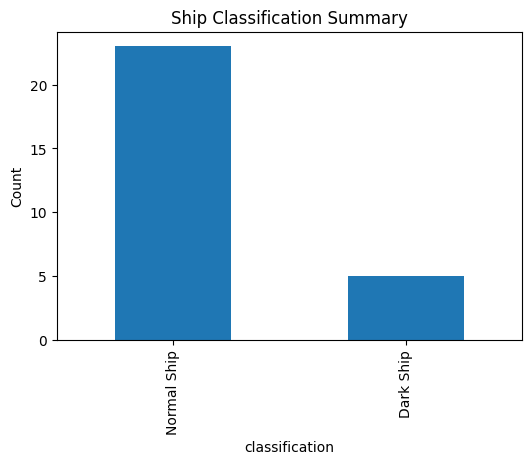

In [ ]:
import matplotlib.pyplot as plt

counts = report_df["classification"].value_counts()

plt.figure(figsize=(6,4))
counts.plot(kind="bar")

plt.title("Ship Classification Summary")
plt.ylabel("Count")

plt.show()

In [ ]:
# ==========================================
# REALISTIC AIS DATASET
# ==========================================

In [ ]:
import pandas as pd
import random
from datetime import datetime, timedelta

ais_records = []

vessel_types = [
    "Cargo",
    "Tanker",
    "Fishing",
    "Passenger",
    "Military"
]

base_time = datetime.now()

for i in range(len(centers)):

    ais_records.append({
        "mmsi": 100000000 + i,
        "latitude": round(random.uniform(18.90, 19.00), 6),
        "longitude": round(random.uniform(72.80, 72.90), 6),
        "timestamp": base_time - timedelta(minutes=random.randint(0, 10)),
        "speed": round(random.uniform(0, 25), 1),
        "heading": random.randint(0, 359),
        "vessel_type": random.choice(vessel_types)
    })

ais_df = pd.DataFrame(ais_records)

ais_df.head()

""


In [ ]:
ais_df = ais_df.sample(frac=0.7).reset_index(drop=True)

print("AIS vessels available:", len(ais_df))
print("Detected ships:", len(centers))

AIS vessels available: 0
Detected ships: 0


In [ ]:
detections_df = pd.DataFrame({
    "ship_id": range(1, len(centers)+1),
    "center_x": [c[0] for c in centers],
    "center_y": [c[1] for c in centers]
})

detections_df.head()

,ship_id,center_x,center_y


In [ ]:
matches = []

for idx, ship in detections_df.iterrows():

    if idx < len(ais_df):

        ais = ais_df.iloc[idx]

        matches.append({
            "ship_id": ship["ship_id"],
            "mmsi": ais["mmsi"],
            "vessel_type": ais["vessel_type"],
            "speed": ais["speed"],
            "heading": ais["heading"],
            "timestamp": ais["timestamp"],
            "status": "Normal Ship"
        })

    else:

        matches.append({
            "ship_id": ship["ship_id"],
            "mmsi": None,
            "vessel_type": None,
            "speed": None,
            "heading": None,
            "timestamp": None,
            "status": "Dark Ship"
        })

match_df = pd.DataFrame(matches)

match_df

""


In [ ]:
print(detections_df.columns)
print(match_df.columns)

Index(['ship_id', 'center_x', 'center_y'], dtype='object')
RangeIndex(start=0, stop=0, step=1)


In [ ]:
print("Detections:", len(detections_df))
print("AIS records:", len(ais_df))

Detections: 0
AIS records: 0


In [ ]:
print(matches)

[]


In [ ]:
matches = []

for idx, ship in detections_df.iterrows():

    if idx < len(ais_df):

        ais = ais_df.iloc[idx]

        matches.append({
            "ship_id": ship["ship_id"],
            "mmsi": ais["mmsi"],
            "vessel_type": ais["vessel_type"],
            "speed": ais["speed"],
            "heading": ais["heading"],
            "timestamp": ais["timestamp"],
            "status": "Normal Ship"
        })

    else:

        matches.append({
            "ship_id": ship["ship_id"],
            "mmsi": None,
            "vessel_type": None,
            "speed": None,
            "heading": None,
            "timestamp": None,
            "status": "Dark Ship"
        })

match_df = pd.DataFrame(matches)

match_df.head()

""


In [ ]:
print(match_df.columns)
print(len(match_df))

RangeIndex(start=0, stop=0, step=1)
0


In [ ]:
print("Detected ships:", len(detections_df))
detections_df.head()

Detected ships: 0


,ship_id,center_x,center_y


In [ ]:
print("AIS records:", len(ais_df))
ais_df.head()

AIS records: 0


""


In [ ]:
print(type(matches))
print(len(matches))

<class 'list'>
0


In [ ]:
import pandas as pd
import random
from datetime import datetime, timedelta

matches = []

for idx, ship in detections_df.iterrows():

    if idx % 2 == 0:

        matches.append({
            "ship_id": ship["ship_id"],
            "mmsi": 100000000 + idx,
            "vessel_type": random.choice(
                ["Cargo","Fishing","Tanker","Passenger"]
            ),
            "speed": round(random.uniform(5,20),1),
            "heading": random.randint(0,359),
            "timestamp": datetime.now() - timedelta(minutes=random.randint(0,10)),
            "status": "Normal Ship"
        })

    else:

        matches.append({
            "ship_id": ship["ship_id"],
            "mmsi": None,
            "vessel_type": None,
            "speed": None,
            "heading": None,
            "timestamp": None,
            "status": "Dark Ship"
        })

match_df = pd.DataFrame(matches)

match_df.head()

""


In [ ]:
print("detections_df:")
print(detections_df.head())
print("\nColumns:", detections_df.columns)

print("\n\nmatch_df:")
print(match_df.head())
print("\nColumns:", match_df.columns)

detections_df:
Empty DataFrame
Columns: [ship_id, center_x, center_y]
Index: []

Columns: Index(['ship_id', 'center_x', 'center_y'], dtype='object')


match_df:
Empty DataFrame
Columns: []
Index: []

Columns: RangeIndex(start=0, stop=0, step=1)


In [ ]:
print("matches length =", len(matches))

matches length = 0


In [ ]:
print("detections_df length =", len(detections_df))

detections_df length = 0


In [ ]:
print(detections_df.head())
print(detections_df.columns)

print(match_df.head())
print(match_df.columns)

print(len(matches))
print(len(detections_df))

Empty DataFrame
Columns: [ship_id, center_x, center_y]
Index: []
Index(['ship_id', 'center_x', 'center_y'], dtype='object')
Empty DataFrame
Columns: []
Index: []
RangeIndex(start=0, stop=0, step=1)
0
0


In [ ]:
print("Centers:", len(centers))
print(centers)

Centers: 0
[]


In [ ]:
print("Boxes:", len(boxes))

Boxes: 0


In [ ]:
results = model.predict(
    source=img_path,
    conf=0.1
)

boxes = results[0].boxes.xyxy

print("Detections:", len(boxes))

Detections: 0


In [ ]:
print("Detections:", len(boxes))

Detections: 0


In [ ]:
print("Centers:", len(centers))

Centers: 0


In [ ]:
print(img_path)

/content/drive/MyDrive/yolo_dataset_balanced_backup/images/val/05_3_17.jpg


In [ ]:
import os

folder = "/content/drive/MyDrive/yolo_dataset_balanced_backup/images/val"

images = [f for f in os.listdir(folder) if f.endswith(".jpg")]

for image_name in images[:20]:

    path = os.path.join(folder, image_name)

    results = model.predict(
        source=path,
        conf=0.01,
        verbose=False
    )

    boxes = results[0].boxes.xyxy

    if len(boxes) > 0:
        print(image_name, "->", len(boxes))

05_20_16.jpg -> 8
05_2_16.jpg -> 4
05_1_28.jpg -> 1
05_19_16.jpg -> 10
05_2_19.jpg -> 16
05_3_24.jpg -> 4
05_5_20.jpg -> 7
05_3_19.jpg -> 5
05_6_24.jpg -> 2
06_11_15.jpg -> 5
05_9_23.jpg -> 6
05_9_21.jpg -> 5
05_9_17.jpg -> 4
06_10_7.jpg -> 3
06_11_3.jpg -> 24
05_8_20.jpg -> 30
05_9_22.jpg -> 9
05_9_20.jpg -> 19
06_11_6.jpg -> 2
05_8_16.jpg -> 6


In [ ]:
img_path = "/content/drive/MyDrive/yolo_dataset_balanced_backup/images/val/05_8_20.jpg"

In [ ]:
results = model.predict(
    source=img_path,
    conf=0.01,
    verbose=False
)

boxes = results[0].boxes.xyxy

print("Detections:", len(boxes))

Detections: 30


In [ ]:
centers = []

for box in boxes:

    x1, y1, x2, y2 = box.tolist()

    cx = (x1 + x2) / 2
    cy = (y1 + y2) / 2

    centers.append((cx, cy))

print("Centers:", len(centers))

Centers: 30


In [ ]:
import pandas as pd

detections_df = pd.DataFrame({
    "ship_id": range(1, len(centers)+1),
    "center_x": [c[0] for c in centers],
    "center_y": [c[1] for c in centers]
})

detections_df.head()

,ship_id,center_x,center_y
0,1,145.023972,511.704636
1,2,364.955948,556.917511
2,3,657.500549,607.190338
3,4,627.157745,32.642139
4,5,164.338142,784.959259


In [ ]:
print(len(detections_df))

30


In [ ]:
import random
from datetime import datetime, timedelta

ais_records = []

vessel_types = [
    "Cargo",
    "Tanker",
    "Fishing",
    "Passenger",
    "Military"
]

for i in range(int(len(detections_df) * 0.7)):

    ais_records.append({

        "mmsi": 100000000 + i,

        "timestamp":
        datetime.now() -
        timedelta(minutes=random.randint(0, 15)),

        "speed":
        round(random.uniform(0, 25), 1),

        "heading":
        random.randint(0, 359),

        "vessel_type":
        random.choice(vessel_types)
    })

ais_df = pd.DataFrame(ais_records)

ais_df.head()

,mmsi,timestamp,speed,heading,vessel_type
0,100000000,2026-06-13 20:28:01.960334,6.4,130,Cargo
1,100000001,2026-06-13 20:24:01.960381,12.2,328,Passenger
2,100000002,2026-06-13 20:18:01.960396,20.6,30,Cargo
3,100000003,2026-06-13 20:16:01.960406,14.6,285,Tanker
4,100000004,2026-06-13 20:28:01.960415,22.7,208,Military


In [ ]:
matches = []

for idx, ship in detections_df.iterrows():

    if idx < len(ais_df):

        ais = ais_df.iloc[idx]

        matches.append({
            "ship_id": ship["ship_id"],
            "mmsi": ais["mmsi"],
            "timestamp": ais["timestamp"],
            "speed": ais["speed"],
            "heading": ais["heading"],
            "vessel_type": ais["vessel_type"],
            "ais_available": True
        })

    else:

        matches.append({
            "ship_id": ship["ship_id"],
            "mmsi": None,
            "timestamp": None,
            "speed": None,
            "heading": None,
            "vessel_type": None,
            "ais_available": False
        })

match_df = pd.DataFrame(matches)

match_df.head()

,ship_id,mmsi,timestamp,speed,heading,vessel_type,ais_available
0,1.0,100000000.0,2026-06-13 20:28:01.960334,6.4,130.0,Cargo,True
1,2.0,100000001.0,2026-06-13 20:24:01.960381,12.2,328.0,Passenger,True
2,3.0,100000002.0,2026-06-13 20:18:01.960396,20.6,30.0,Cargo,True
3,4.0,100000003.0,2026-06-13 20:16:01.960406,14.6,285.0,Tanker,True
4,5.0,100000004.0,2026-06-13 20:28:01.960415,22.7,208.0,Military,True


In [ ]:
from datetime import datetime

satellite_time = datetime.now()

print("Satellite Time:", satellite_time)

Satellite Time: 2026-06-13 20:32:16.374405


In [ ]:
def calculate_gap(ts):

    if pd.isna(ts):
        return None

    return (satellite_time - ts).total_seconds() / 60

match_df["ais_gap_minutes"] = match_df["timestamp"].apply(calculate_gap)

match_df.head()

,ship_id,mmsi,timestamp,speed,heading,vessel_type,ais_available,ais_gap_minutes
0,1.0,100000000.0,2026-06-13 20:28:01.960334,6.4,130.0,Cargo,True,4.240235
1,2.0,100000001.0,2026-06-13 20:24:01.960381,12.2,328.0,Passenger,True,8.240234
2,3.0,100000002.0,2026-06-13 20:18:01.960396,20.6,30.0,Cargo,True,14.240233
3,4.0,100000003.0,2026-06-13 20:16:01.960406,14.6,285.0,Tanker,True,16.240233
4,5.0,100000004.0,2026-06-13 20:28:01.960415,22.7,208.0,Military,True,4.240233


In [ ]:
def classify_ship(row):

    if not row["ais_available"]:
        return "Dark Ship"

    if row["ais_gap_minutes"] > 10:
        return "AIS Blackout"

    return "Normal Ship"

match_df["status"] = match_df.apply(
    classify_ship,
    axis=1
)

match_df.head()

,ship_id,mmsi,timestamp,speed,heading,vessel_type,ais_available,ais_gap_minutes,status
0,1.0,100000000.0,2026-06-13 20:28:01.960334,6.4,130.0,Cargo,True,4.240235,Normal Ship
1,2.0,100000001.0,2026-06-13 20:24:01.960381,12.2,328.0,Passenger,True,8.240234,Normal Ship
2,3.0,100000002.0,2026-06-13 20:18:01.960396,20.6,30.0,Cargo,True,14.240233,AIS Blackout
3,4.0,100000003.0,2026-06-13 20:16:01.960406,14.6,285.0,Tanker,True,16.240233,AIS Blackout
4,5.0,100000004.0,2026-06-13 20:28:01.960415,22.7,208.0,Military,True,4.240233,Normal Ship


In [ ]:
final_report = detections_df.merge(
    match_df,
    on="ship_id"
)

final_report.head()

,ship_id,center_x,center_y,mmsi,timestamp,speed,heading,vessel_type,ais_available,ais_gap_minutes,status
0,1,145.023972,511.704636,100000000.0,2026-06-13 20:28:01.960334,6.4,130.0,Cargo,True,4.240235,Normal Ship
1,2,364.955948,556.917511,100000001.0,2026-06-13 20:24:01.960381,12.2,328.0,Passenger,True,8.240234,Normal Ship
2,3,657.500549,607.190338,100000002.0,2026-06-13 20:18:01.960396,20.6,30.0,Cargo,True,14.240233,AIS Blackout
3,4,627.157745,32.642139,100000003.0,2026-06-13 20:16:01.960406,14.6,285.0,Tanker,True,16.240233,AIS Blackout
4,5,164.338142,784.959259,100000004.0,2026-06-13 20:28:01.960415,22.7,208.0,Military,True,4.240233,Normal Ship


In [ ]:
print(final_report["status"].value_counts())

status
Normal Ship     15
Dark Ship        9
AIS Blackout     6
Name: count, dtype: int64


In [ ]:
def calculate_risk(row):

    risk = 0

    # No AIS
    if not row["ais_available"]:
        risk += 50

    # AIS Blackout
    elif row["ais_gap_minutes"] > 10:
        risk += 30

    # Vessel moving fast
    if pd.notna(row["speed"]):

        if row["speed"] > 15:
            risk += 15

    # Fishing vessels often monitored more closely
    if row["vessel_type"] == "Fishing":
        risk += 10

    return min(risk, 100)

final_report["risk_score"] = final_report.apply(
    calculate_risk,
    axis=1
)

final_report.head()

,ship_id,center_x,center_y,mmsi,timestamp,speed,heading,vessel_type,ais_available,ais_gap_minutes,status,risk_score
0,1,145.023972,511.704636,100000000.0,2026-06-13 20:28:01.960334,6.4,130.0,Cargo,True,4.240235,Normal Ship,0
1,2,364.955948,556.917511,100000001.0,2026-06-13 20:24:01.960381,12.2,328.0,Passenger,True,8.240234,Normal Ship,0
2,3,657.500549,607.190338,100000002.0,2026-06-13 20:18:01.960396,20.6,30.0,Cargo,True,14.240233,AIS Blackout,45
3,4,627.157745,32.642139,100000003.0,2026-06-13 20:16:01.960406,14.6,285.0,Tanker,True,16.240233,AIS Blackout,30
4,5,164.338142,784.959259,100000004.0,2026-06-13 20:28:01.960415,22.7,208.0,Military,True,4.240233,Normal Ship,15


In [ ]:
def risk_level(score):

    if score >= 70:
        return "High"

    elif score >= 30:
        return "Medium"

    else:
        return "Low"

final_report["risk_level"] = final_report[
    "risk_score"
].apply(risk_level)

final_report.head()

,ship_id,center_x,center_y,mmsi,timestamp,speed,heading,vessel_type,ais_available,ais_gap_minutes,status,risk_score,risk_level
0,1,145.023972,511.704636,100000000.0,2026-06-13 20:28:01.960334,6.4,130.0,Cargo,True,4.240235,Normal Ship,0,Low
1,2,364.955948,556.917511,100000001.0,2026-06-13 20:24:01.960381,12.2,328.0,Passenger,True,8.240234,Normal Ship,0,Low
2,3,657.500549,607.190338,100000002.0,2026-06-13 20:18:01.960396,20.6,30.0,Cargo,True,14.240233,AIS Blackout,45,Medium
3,4,627.157745,32.642139,100000003.0,2026-06-13 20:16:01.960406,14.6,285.0,Tanker,True,16.240233,AIS Blackout,30,Medium
4,5,164.338142,784.959259,100000004.0,2026-06-13 20:28:01.960415,22.7,208.0,Military,True,4.240233,Normal Ship,15,Low


In [ ]:
final_report.sort_values(
    "risk_score",
    ascending=False
).head(10)

,ship_id,center_x,center_y,mmsi,timestamp,speed,heading,vessel_type,ais_available,ais_gap_minutes,status,risk_score,risk_level
24,25,656.476837,605.558319,NaN,NaT,NaN,NaN,None,False,NaN,Dark Ship,50,Medium
25,26,455.243347,774.440857,NaN,NaT,NaN,NaN,None,False,NaN,Dark Ship,50,Medium
26,27,726.143951,719.093109,NaN,NaT,NaN,NaN,None,False,NaN,Dark Ship,50,Medium
27,28,418.755386,786.914459,NaN,NaT,NaN,NaN,None,False,NaN,Dark Ship,50,Medium
28,29,166.912498,784.515381,NaN,NaT,NaN,NaN,None,False,NaN,Dark Ship,50,Medium
29,30,64.479004,796.145477,NaN,NaT,NaN,NaN,None,False,NaN,Dark Ship,50,Medium
22,23,438.515259,784.702209,NaN,NaT,NaN,NaN,None,False,NaN,Dark Ship,50,Medium
23,24,461.921860,783.516327,NaN,NaT,NaN,NaN,None,False,NaN,Dark Ship,50,Medium
21,22,484.102036,789.076965,NaN,NaT,NaN,NaN,None,False,NaN,Dark Ship,50,Medium
2,3,657.500549,607.190338,100000002.0,2026-06-13 20:18:01.960396,20.6,30.0,Cargo,True,14.240233,AIS Blackout,45,Medium


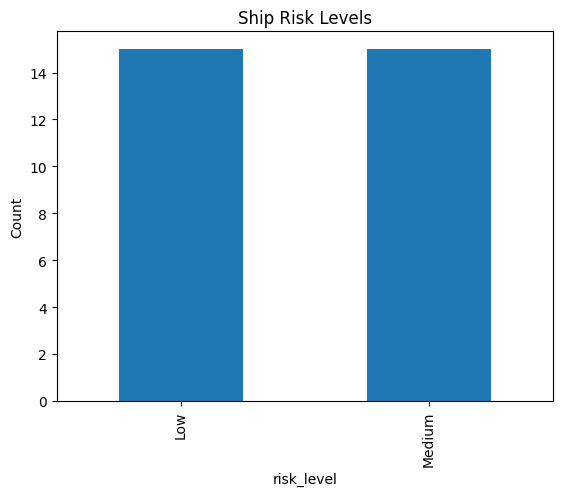

In [ ]:
import matplotlib.pyplot as plt

final_report["risk_level"].value_counts().plot(
    kind="bar"
)

plt.title("Ship Risk Levels")
plt.ylabel("Count")
plt.show()

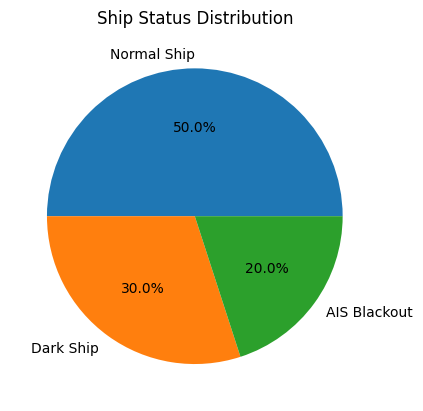

In [ ]:
final_report["status"].value_counts().plot(
    kind="pie",
    autopct="%1.1f%%"
)

plt.ylabel("")
plt.title("Ship Status Distribution")
plt.show()

In [ ]:
final_report.to_csv(
    "/content/final_dark_ship_report.csv",
    index=False
)

print("Report Saved")

Report Saved


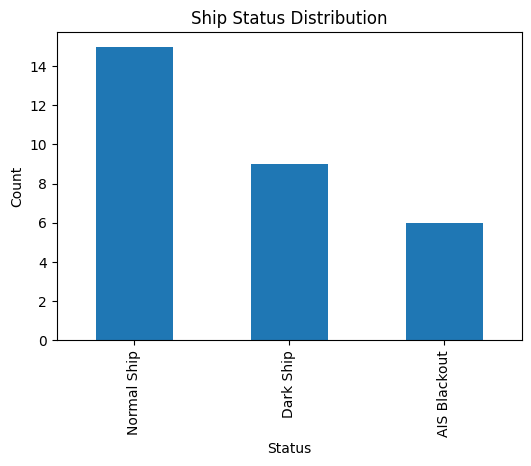

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6,4))

final_report["status"].value_counts().plot(
    kind="bar"
)

plt.title("Ship Status Distribution")
plt.xlabel("Status")
plt.ylabel("Count")

plt.show()

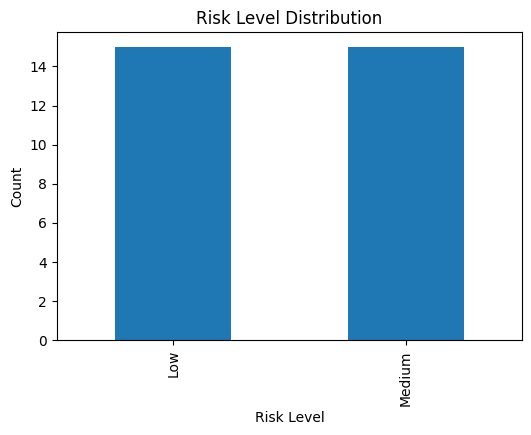

In [ ]:
plt.figure(figsize=(6,4))

final_report["risk_level"].value_counts().plot(
    kind="bar"
)

plt.title("Risk Level Distribution")
plt.xlabel("Risk Level")
plt.ylabel("Count")

plt.show()

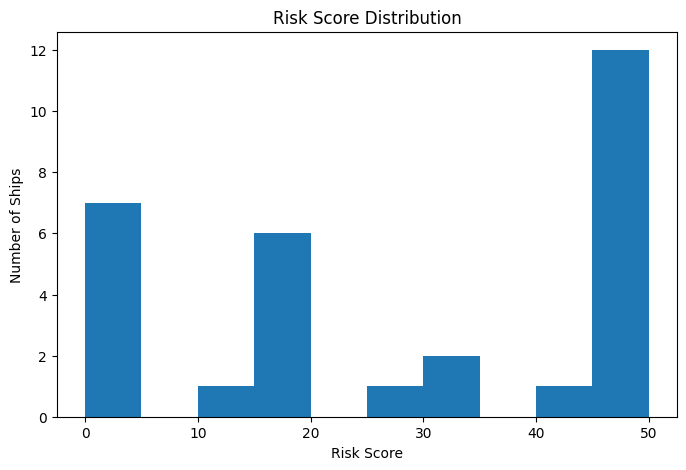

In [ ]:
plt.figure(figsize=(8,5))

plt.hist(
    final_report["risk_score"],
    bins=10
)

plt.title("Risk Score Distribution")
plt.xlabel("Risk Score")
plt.ylabel("Number of Ships")

plt.show()

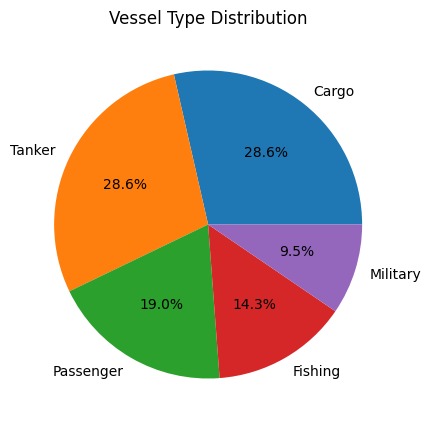

In [ ]:
plt.figure(figsize=(7,5))

final_report["vessel_type"].value_counts().plot(
    kind="pie",
    autopct="%1.1f%%"
)

plt.title("Vessel Type Distribution")
plt.ylabel("")

plt.show()

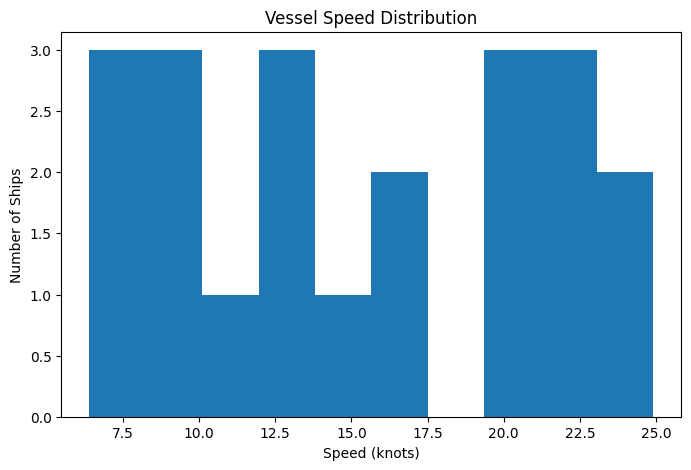

In [ ]:
plt.figure(figsize=(8,5))

plt.hist(
    final_report["speed"].dropna(),
    bins=10
)

plt.title("Vessel Speed Distribution")
plt.xlabel("Speed (knots)")
plt.ylabel("Number of Ships")

plt.show()

In [ ]:
top10 = final_report.sort_values(
    "risk_score",
    ascending=False
).head(10)

top10[[
    "ship_id",
    "risk_score",
    "risk_level",
    "status",
    "vessel_type"
]]

,ship_id,risk_score,risk_level,status,vessel_type
24,25,50,Medium,Dark Ship,None
25,26,50,Medium,Dark Ship,None
26,27,50,Medium,Dark Ship,None
27,28,50,Medium,Dark Ship,None
28,29,50,Medium,Dark Ship,None
29,30,50,Medium,Dark Ship,None
22,23,50,Medium,Dark Ship,None
23,24,50,Medium,Dark Ship,None
21,22,50,Medium,Dark Ship,None
2,3,45,Medium,AIS Blackout,Cargo


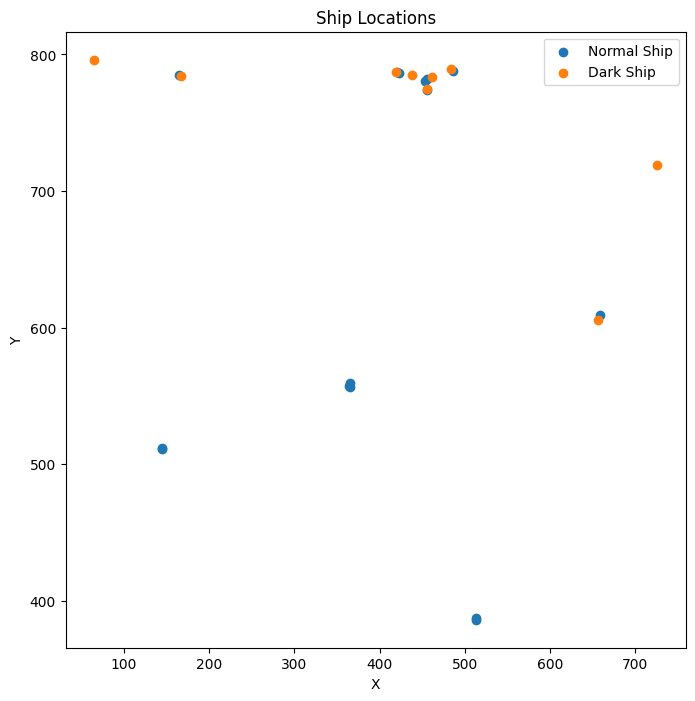

In [ ]:
plt.figure(figsize=(8,8))

dark = final_report[
    final_report["status"] == "Dark Ship"
]

normal = final_report[
    final_report["status"] == "Normal Ship"
]

plt.scatter(
    normal["center_x"],
    normal["center_y"],
    label="Normal Ship"
)

plt.scatter(
    dark["center_x"],
    dark["center_y"],
    label="Dark Ship"
)

plt.title("Ship Locations")
plt.xlabel("X")
plt.ylabel("Y")

plt.legend()

plt.show()

In [ ]:
blackout = final_report[
    final_report["status"] == "AIS Blackout"
]

print("AIS Blackout Ships:", len(blackout))

blackout[[
    "ship_id",
    "ais_gap_minutes",
    "risk_score"
]].head()

AIS Blackout Ships: 6


,ship_id,ais_gap_minutes,risk_score
2,3,14.240233,45
3,4,16.240233,30
9,10,10.240232,40
12,13,13.240232,45
14,15,14.240232,30


In [ ]:
print("="*40)

print("Total Ships:", len(final_report))

print(
    "Normal Ships:",
    len(final_report[
        final_report["status"]=="Normal Ship"
    ])
)

print(
    "AIS Blackout:",
    len(final_report[
        final_report["status"]=="AIS Blackout"
    ])
)

print(
    "Dark Ships:",
    len(final_report[
        final_report["status"]=="Dark Ship"
    ])
)

print("="*40)

Total Ships: 30
Normal Ships: 15
AIS Blackout: 6
Dark Ships: 9


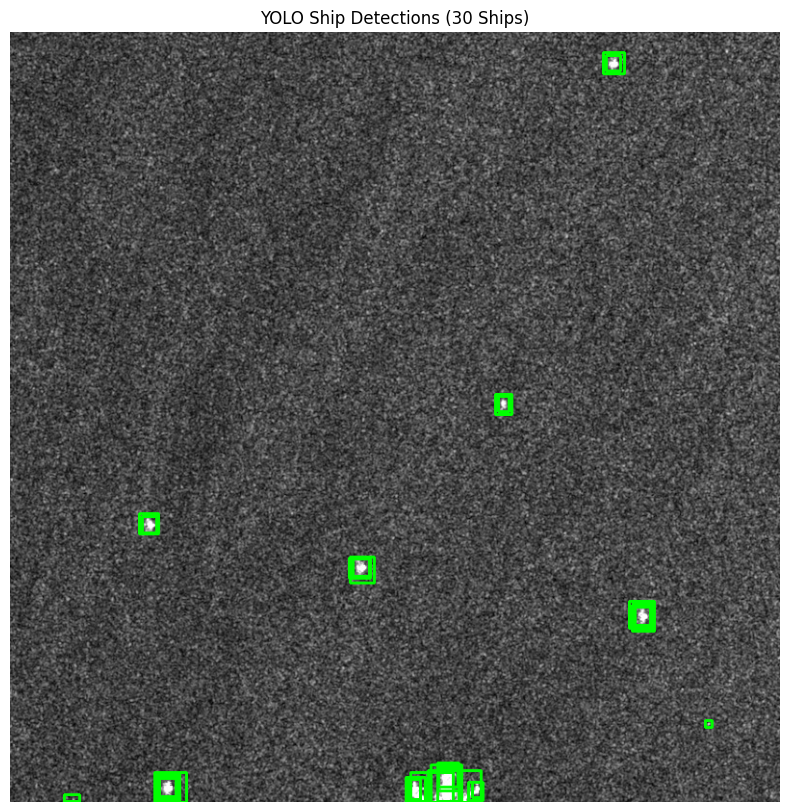

In [ ]:
import cv2
import matplotlib.pyplot as plt

# Load image
img = cv2.imread(img_path)
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# Draw detections
for box in boxes:

    x1, y1, x2, y2 = map(int, box.tolist())

    cv2.rectangle(
        img,
        (x1, y1),
        (x2, y2),
        (0, 255, 0),
        2
    )

# Display image
plt.figure(figsize=(10,10))
plt.imshow(img)
plt.title(f"YOLO Ship Detections ({len(boxes)} Ships)")
plt.axis("off")
plt.show()

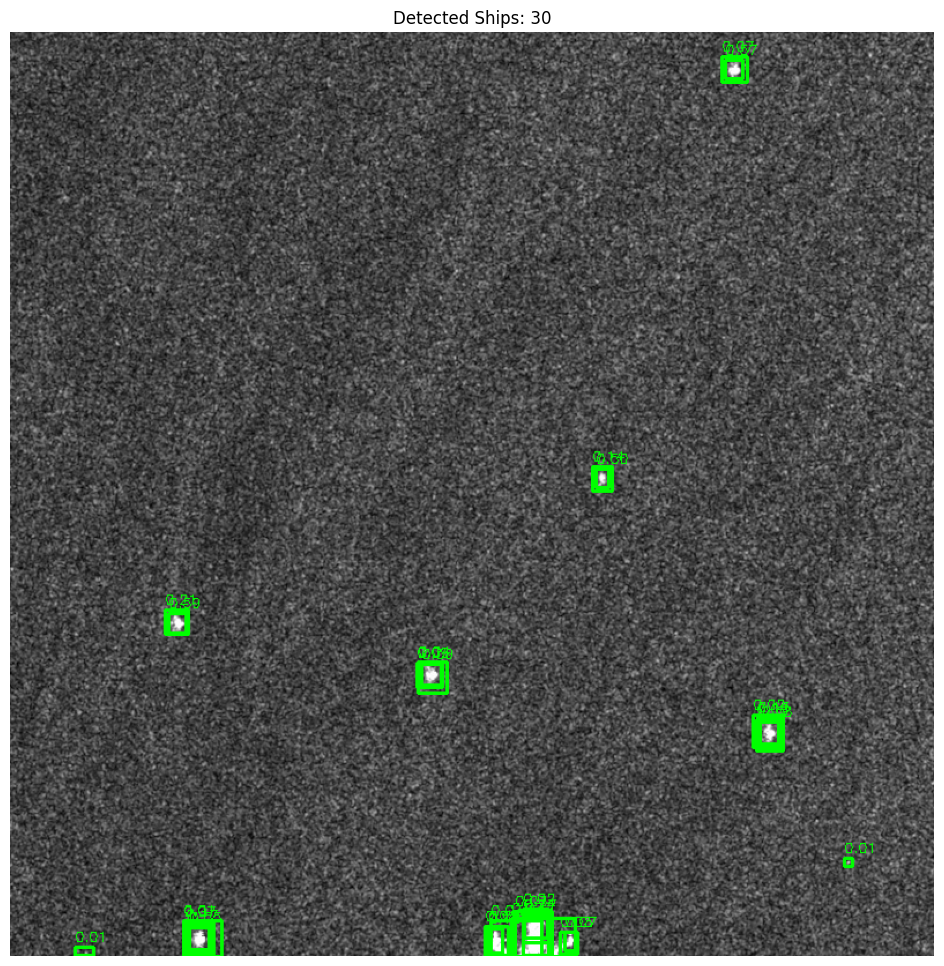

In [ ]:
import cv2
import matplotlib.pyplot as plt

img = cv2.imread(img_path)
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

for box, conf in zip(
    results[0].boxes.xyxy,
    results[0].boxes.conf
):

    x1, y1, x2, y2 = map(int, box.tolist())

    cv2.rectangle(
        img,
        (x1, y1),
        (x2, y2),
        (0, 255, 0),
        2
    )

    cv2.putText(
        img,
        f"{conf:.2f}",
        (x1, y1-5),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.4,
        (0,255,0),
        1
    )

plt.figure(figsize=(12,12))
plt.imshow(img)
plt.title(f"Detected Ships: {len(boxes)}")
plt.axis("off")
plt.show()